# 13 · Part 1: дизайн теста для high-value сегмента

Шаги 2–10 плана Part 1. Гипотеза: персонализированная механика для high-value
сегмента LTV поднимает долю клиентов с повторной покупкой в 90 дней. Считаю
базовый уровень, MDE, требуемый размер выборки, CUPED и вред от подглядывания.
Числа — из LTV-данных, а не из головы.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
sys.path.insert(0, '../../case_ltv/src')
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from paths import CASE_AB, PROCESSED, RANDOM_SEED, figures
from features import build_target, CUTOFF_DATE
from experiment import wilson_ci
FIG = figures(CASE_AB); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
split = pd.read_parquet(PROCESSED / 'ltv_split.parquet')
seg = pd.read_parquet(PROCESSED / 'segments.parquet')
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')
t90 = build_target(tx, split.index, CUTOFF_DATE, 3).add_prefix('d90_')
d = split.join(seg[['high_value', 'BG']]).join(t90)
d['repeat90'] = (d.d90_revenue_holdout > 0).astype(int)
print('клиентов:', len(d), '· high-value:', int(d.high_value.sum()))
print('repeat90 overall:', round(d.repeat90.mean(), 4))

клиентов: 4239 · high-value: 417
repeat90 overall: 0.3298


## Базовый уровень по сегментам

High-value определён в LTV-кейсе: порог £3 580 по прогнозному LTV, 417 клиентов.
Для сравнения — верхние 20/30/50 % по прогнозу и вся база. Метрика — доля
клиентов с покупкой в первые 90 дней holdout.

In [2]:
def segment_row(label, mask):
    sub = d[mask]
    p = sub.repeat90.mean()
    n = len(sub)
    return {
        'segment': label,
        'n': n,
        'repeat90': p,
        'ci_low': wilson_ci(sub.repeat90.sum(), n)[0],
        'ci_high': wilson_ci(sub.repeat90.sum(), n)[1],
        'revenue_mean': sub.d90_revenue_holdout.mean(),
        'revenue_sd': sub.d90_revenue_holdout.std(),
    }

rows = [segment_row('high-value (£3 580)', d.high_value)]
for q in [0.20, 0.30, 0.50]:
    rows.append(segment_row(f'top {int(q*100)} %', d.BG >= d.BG.quantile(1 - q)))
rows.append(segment_row('all', np.ones(len(d), dtype=bool)))
seg_table = pd.DataFrame(rows)
seg_table.round(3)


,segment,n,repeat90,ci_low,ci_high,revenue_mean,revenue_sd
0,high-value (£3 580),417,0.763,0.719,0.801,1960.872,4519.159
1,top 20 %,848,0.667,0.635,0.698,1173.078,3291.087
2,top 30 %,1272,0.596,0.569,0.623,861.684,2733.026
3,top 50 %,2120,0.495,0.474,0.516,572.429,2152.537
4,all,4239,0.330,0.316,0.344,311.763,1549.358


## MDE и размер выборки

Для двух пропорций при alpha = 0.05 и power = 0.80:
`MDE = (z_{1−α/2} + z_{1−β}) · sqrt(2p(1−p)/n_arm)`.
Требуемый `n_arm` для заданного MDE — обратная формула. Для revenue —
`n_arm = 2(z)^2 σ² / Δ²`, где Δ — 10 % от среднего.

In [3]:
Z = norm.ppf(0.975) + norm.ppf(0.8)

def mde_two_prop(p, n_arm):
    return Z * np.sqrt(2 * p * (1 - p) / n_arm)

def n_arm_two_prop(p, mde):
    return 2 * p * (1 - p) * (Z / mde) ** 2

def n_arm_revenue(mean, sd, relative_lift=0.10):
    delta = relative_lift * mean
    return 2 * (Z ** 2) * sd ** 2 / delta ** 2

seg_table['mde_pp_at_n'] = seg_table.apply(
    lambda r: mde_two_prop(r.repeat90, r.n / 2) * 100, axis=1)
seg_table['n_arm_2pp'] = seg_table.repeat90.apply(lambda p: n_arm_two_prop(p, 0.02))
seg_table['n_arm_5pp'] = seg_table.repeat90.apply(lambda p: n_arm_two_prop(p, 0.05))
seg_table['n_arm_rev10'] = seg_table.apply(
    lambda r: n_arm_revenue(r.revenue_mean, r.revenue_sd), axis=1)
seg_table.round(3)


,segment,n,repeat90,ci_low,ci_high,revenue_mean,revenue_sd,mde_pp_at_n,n_arm_2pp,n_arm_5pp,n_arm_rev10
0,high-value (£3 580),417,0.763,0.719,0.801,1960.872,4519.159,11.675,7105.062,1136.810,8337.860
1,top 20 %,848,0.667,0.635,0.698,1173.078,3291.087,9.065,8710.669,1393.707,12355.567
2,top 30 %,1272,0.596,0.569,0.623,861.684,2733.026,7.709,9450.086,1512.014,15791.697
3,top 50 %,2120,0.495,0.474,0.516,572.429,2152.537,6.084,9810.043,1569.607,22197.065
4,all,4239,0.330,0.316,0.344,311.763,1549.358,4.046,8674.196,1387.871,38769.557


## CUPED на исторической выручке

Ковариата — `revenue_cal` (выручка калибровки до cutoff). CUPED снижает
дисперсию на `1 − ρ²`, где ρ — корреляция ковариаты с исходом. Для бинарного
`repeat90` корреляция слабая; выигрыш почти нулевой.

In [4]:
hv = d[d.high_value]
rho = hv[['revenue_cal', 'repeat90']].corr().iloc[0, 1]
var_reduction = rho ** 2
mde_base = mde_two_prop(hv.repeat90.mean(), len(hv) / 2)
mde_cuped = mde_base * np.sqrt(1 - var_reduction)
print('rho:', round(rho, 4), '· variance reduction:', f'{var_reduction:.2%}',
      '· MDE base:', f'{mde_base*100:.2f} п.п.',
      '· MDE CUPED:', f'{mde_cuped*100:.2f} п.п.')


rho: 0.1112 · variance reduction: 1.24% · MDE base: 11.68 п.п. · MDE CUPED: 11.60 п.п.


## Кривая MDE против n

Точка на графике — high-value сегмент (n/2 = 208 на arm); горизонтали — 2 и
5 п.п. Видно, что для 2 п.п. нужен на порядок больший поток.

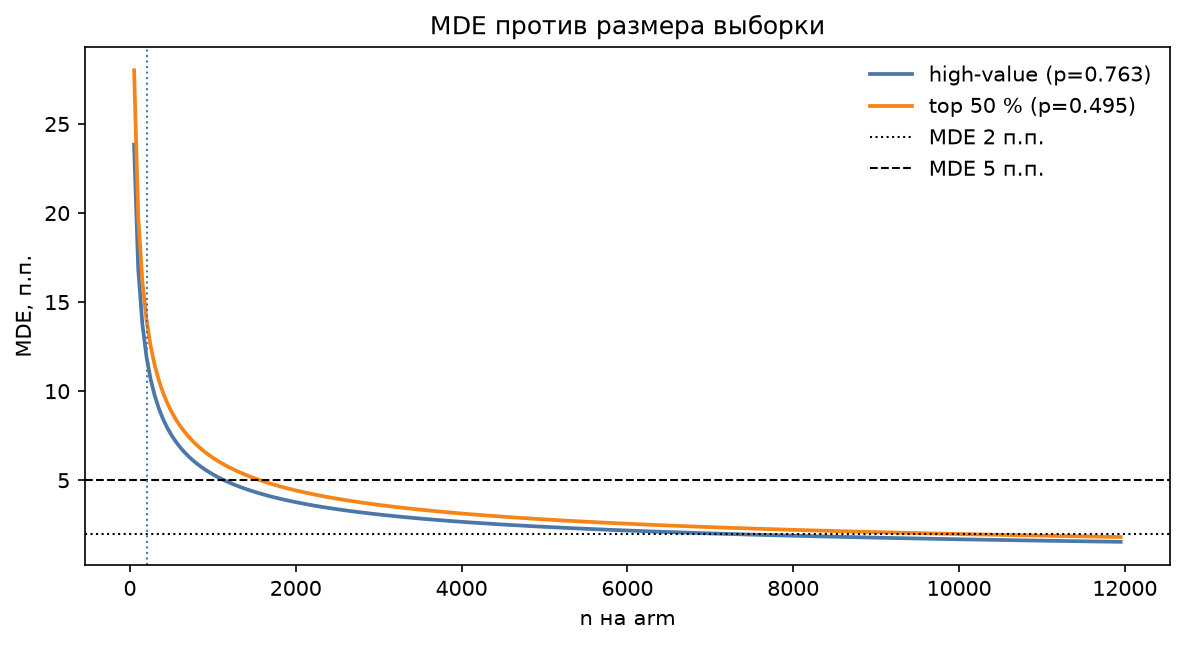

In [5]:
n_grid = np.arange(50, 12000, 50)
fig, ax = plt.subplots(figsize=(8, 4.4), dpi=150)
for label, p, color in [('high-value (p=0.763)', hv.repeat90.mean(), '#4C78A8'),
                        ('top 50 % (p=0.495)', d[d.BG >= d.BG.quantile(0.5)].repeat90.mean(), '#F58518')]:
    ax.plot(n_grid, mde_two_prop(p, n_grid) * 100, lw=1.8, color=color, label=label)
ax.axhline(2, color='black', ls=':', lw=1, label='MDE 2 п.п.')
ax.axhline(5, color='black', ls='--', lw=1, label='MDE 5 п.п.')
ax.axvline(len(hv) / 2, color='#4C78A8', ls=':', lw=1)
ax.set(xlabel='n на arm', ylabel='MDE, п.п.', title='MDE против размера выборки')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / '06-mde-vs-n.png'); plt.show()


## Подглядывание

Симулирую 20 000 траекторий Z-статистики под H0 с 20 промежуточными взглядами.
Если каждый взгляд проверять при α = 0.05, доля хотя бы одного ложного
срабатывания резко растёт. Это аргумент за фиксированный горизонт или
alpha spending.

FPR fixed horizon: 0.050 · FPR 20 looks: 0.250


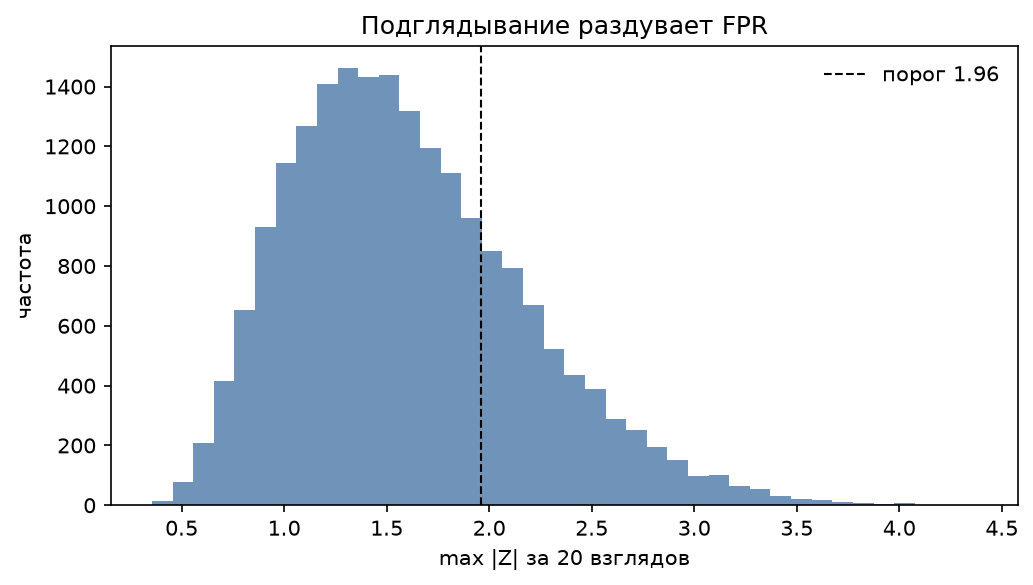

In [6]:
n_sim, n_looks = 20000, 20
z_paths = np.cumsum(RNG.normal(size=(n_sim, n_looks)), axis=1) / np.sqrt(np.arange(1, n_looks + 1))
max_abs = np.abs(z_paths).max(axis=1)
fpr_peek = (max_abs > norm.ppf(0.975)).mean()
fpr_fixed = (np.abs(z_paths[:, -1]) > norm.ppf(0.975)).mean()
print('FPR fixed horizon:', f'{fpr_fixed:.3f}', '· FPR 20 looks:', f'{fpr_peek:.3f}')
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.hist(max_abs, bins=40, color='#4C78A8', alpha=.8)
ax.axvline(norm.ppf(0.975), color='black', ls='--', lw=1, label='порог 1.96')
ax.set(xlabel='max |Z| за 20 взглядов', ylabel='частота', title='Подглядывание раздувает FPR')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / '07-peeking-fpr.png'); plt.show()


## Вывод дизайна

- High-value сегмент: 417 клиентов, baseline 76.3 %, MDE при 208/arm — 11.7 п.п.
- Для 5 п.п. нужно 1 137/arm (2 274 клиента), для 2 п.п. — 7 105/arm.
  Сегмент слишком мал и близок к потолку: классический тест на нём не
  обеспечивает мощность под реалистичный эффект.
- CUPED на исторической выручке даёт ρ = 0.111 и снижение дисперсии 1.2 % —
  почти ничего.
- Revenue как primary требует 8 278/arm на 10 % lift: хвост распределения
  съедает выигрыш.
- Подглядывание при 20 взглядах даёт FPR 25 % вместо 5 %.
- Рекомендация: тестировать более широкий сегмент (top 30–50 %) с repeat rate
  как primary, либо принять MDE ~5 п.п. и больший поток, либо использовать
  matched control / switchback для high-value. Фиксированный горизонт 90 дней,
  без подглядывания; secondary и guardrails — Holm.

In [7]:
design = {
    'unit': 'customer_id',
    'primary': 'repeat purchase in 90 days',
    'secondary': '90-day net revenue per customer',
    'guardrails': ['margin', 'CAC', 'refund rate', 'unsubscribe rate'],
    'alpha': 0.05,
    'power': 0.80,
    'segment': 'high-value LTV (417)',
    'baseline_repeat90': float(hv.repeat90.mean()),
    'mde_pp_at_current_n': float(mde_base * 100),
    'n_arm_5pp': float(n_arm_two_prop(hv.repeat90.mean(), 0.05)),
    'n_arm_2pp': float(n_arm_two_prop(hv.repeat90.mean(), 0.02)),
    'cuped_rho': float(rho),
    'cuped_variance_reduction': float(var_reduction),
    'peeking_fpr_20_looks': float(fpr_peek),
    'decision': 'broaden segment or change design; classic test on 417 is underpowered',
}
(PROCESSED / 'cookie_cats_design.json').write_text(
    json.dumps(design, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(design, ensure_ascii=False, indent=2))


{
  "unit": "customer_id",
  "primary": "repeat purchase in 90 days",
  "secondary": "90-day net revenue per customer",
  "guardrails": [
    "margin",
    "CAC",
    "refund rate",
    "unsubscribe rate"
  ],
  "alpha": 0.05,
  "power": 0.8,
  "segment": "high-value LTV (417)",
  "baseline_repeat90": 0.762589928057554,
  "mde_pp_at_current_n": 11.675108029945044,
  "n_arm_5pp": 1136.809950240799,
  "n_arm_2pp": 7105.062189004997,
  "cuped_rho": 0.11122780383318402,
  "cuped_variance_reduction": 0.012371624345553266,
  "peeking_fpr_20_looks": 0.2501,
  "decision": "broaden segment or change design; classic test on 417 is underpowered"
}
